In [32]:
%load_ext autoreload
%autoreload 2

import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import Counter

from tpa.tractometry.parametrization import *
from tpa.utils.utils import *
from tpa.utils.io import *
from tpa.utils.viz import alternating_colors, plot_uvecs

setup_logging()
sns.set_style("darkgrid") 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from dipy.io.image import load_nifti

def load_atlas_bundle(bundle):
    bundle_dir="/Volumes/faculty/thompson/four_d/wfeng/Datasets/Atlas/ENIGMA_tract_atlas_v2/bundles_downsampled"
    streamlines, _  = load_streamlines(f"{bundle_dir}/{bundle}.trk")
    return streamlines

def load_subj_bundle_pairs(subj, bundle):
    org_bundle_fpath=f"/Volumes/faculty/thompson/FiberNET/tractography_datasets/ADNI_new/derivatives/{subj}/lbt_enigma_prob/org_bundles/{bundle}.trk"
    rec_bundle_fpath=f"/Volumes/faculty/thompson/FiberNET/tractography_datasets/ADNI_new/derivatives/{subj}/lbt_enigma_prob/rec_bundles/{bundle}.trk"
    org_bundle, _  = load_streamlines(org_bundle_fpath)
    rec_bundle, _  = load_streamlines(rec_bundle_fpath)
    return org_bundle, rec_bundle

def load_subj_fa(subj):
    fa_fpath=f"/Volumes/faculty/thompson/FiberNET/tractography_datasets/ADNI_new/derivatives/{subj}/lbt_enigma_prob/dti/fa.nii.gz"
    fa, affine = load_nifti(fa_fpath)
    return fa, affine

In [87]:
bundle_name = "CC_Body_Pre"
atlas_bundle = load_atlas_bundle(bundle_name)
print(len(atlas_bundle))

5415


In [88]:
subj = "002_S_1155_20170424_A3_DWI_S55"
fa, affine = load_subj_fa(subj)
org_bundle, rec_bundle = load_subj_bundle_pairs(subj, bundle_name)
print(len(org_bundle))

4909


### Multiple centroid (IGNORE)

Might as well split the bundle before parametrization

In [ ]:
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from scipy.ndimage import gaussian_filter1d
from collections import Counter
from nibabel.streamlines.array_sequence import ArraySequence
from dipy.tracking.streamline import set_number_of_points, Streamlines, values_from_volume
from dipy.tracking.utils import length
from dipy.segment.metric import AveragePointwiseEuclideanMetric
from dipy.segment.clustering import QuickBundles
from dipy.align.bundlemin import distance_matrix_mdf

def bundle_centroid(bundle, n_points=50, thresh=30):
    '''Get bundle centroid(s) from a bundle with a given distance threshold'''
    if isinstance(bundle, np.ndarray):
        bundle = ArraySequence(bundle[:,:,:3])
        
    ref_bundle = set_number_of_points(bundle, nb_points=n_points)
    metric = AveragePointwiseEuclideanMetric()
    qb = QuickBundles(threshold=thresh, metric=metric)
    clusters = qb.cluster(ref_bundle)
    centroids = Streamlines(clusters.centroids)
    return centroids
    # logging.info(f"Produced {len(centroids)} centroids")
    # lens = np.asarray(list(length(centroids)))
    # return centroids[np.argmax(lens)]

def closest_centroid(bundle, centroids, n_points=50):
    '''Return the index of the closest centroid for each streamline in a bundle'''
    bundle = set_number_of_points(bundle, nb_points=n_points)
    centroids = set_number_of_points(centroids, nb_points=n_points)
    dist = distance_matrix_mdf(bundle, centroids)
    return np.argmin(dist, axis=1)

def along_tract_assignment(bundle, centroids, assignments=None):
    if assignments is None:
        assignments = closest_centroid(bundle, centroids)
    s_index = []
    for i, line in enumerate(bundle):
        c_closest = centroids[assignments[i]]
        _, idx = cKDTree(c_closest, 1).query(line, k=1)
        s_index.append(idx)
    return np.concatenate(s_index)

def parametrize_bundle_signed_multi(bundle, ref_bundle, s_len=5, r_len=5, centroid_thresh=30):

    # Along-tract assignment based on distance to the closest point on the closest centroid
    ns = get_n_segment_by_length(ref_bundle, s_len)
    centroids = bundle_centroid(ref_bundle, n_points=ns, thresh=centroid_thresh)
    logging.info(f"Computed {len(centroids)} centroids and {ns} segments from the reference bundle")
    assignments = closest_centroid(bundle, centroids)
    s_index = along_tract_assignment(bundle, centroids, assignments=assignments)
    assignments_points = np.repeat(assignments, np.array([len(line) for line in bundle]))

    # Set up
    r_vecs_all = []
    tangents_all = []
    points = bundle.get_data()
    r_signed_all = np.zeros(len(points))

    # Iterate over each centroid
    for c_idx, c_line in enumerate(centroids):

        # Calculate centroid tangents
        tangent = np.gradient(c_line, axis=0)
        tangent /= np.linalg.norm(tangent, axis=1, keepdims=True)
        tangents_all.append(tangent)

        mask = (assignments_points == c_idx)
        if not np.any(mask):
            continue     
        c_points = points[mask]     # bundle points assigned to this centroid
        s_index_c = s_index[mask]   # segment assingment for points assigned to this centroid

        # Get bundle points assignment to the segment and compute r_vecs
        r_vecs = np.zeros_like(c_line)
        for s in range(ns):
            seg_idx = (s_index_c == s)
            seg_pts = c_points[seg_idx]
            if len(seg_pts) < 3:
                r_vecs[s] = np.array([0,0,0])
                continue
            d = seg_pts - c_line[s]
            d_proj = d - np.outer(np.dot(d, tangent[s]), tangent[s])
            pca = PCA(n_components=1).fit(d_proj)
            r_vecs[s] = pca.components_[0]
    
        # Flip to ensure r_vecs are continuous along-tract
        for s in range(1, ns):
            if np.dot(r_vecs[s], r_vecs[s-1]) < 0:
                r_vecs[s] = -r_vecs[s]
    
        # Gaussian smoothing and normalize
        r_vecs = gaussian_filter1d(r_vecs, sigma=1, axis=0)
        r_vecs /= np.linalg.norm(r_vecs, axis=1, keepdims=True)
        r_vecs_all.append(r_vecs)

    r_vecs_all, centroids = np.stack(r_vecs_all), np.stack(centroids)

    # Flip r_vecs to ensure consistency across centroids
    ref_r_vec = r_vecs_all[0, ns//2]  # use the midpoint r_vec from the first centroid as reference
    for c in range(1, len(centroids)):
        if np.dot(r_vecs_all[c, ns//2], ref_r_vec) < 0:
            logging.info(f"Flip r_vec for centroid {c}/{len(centroids)}")
            r_vecs_all[c,:] *= -1

    return r_vecs_all, centroids
    
    # Compute radial distances and bins
    # delta = c_points - c_line[s_index_c]
    # r_signed_all[mask] = np.sum(delta * r_vecs[s_index_c], axis=1)

r_vecs_all, centroids = parametrize_bundle_signed_multi(subj_bundle, atlas_bundle, s_len=5, r_len=5, centroid_thresh=20)

2025-11-04 16:13:14,992 [INFO] root: Computed 1 centroids and 17 segments from the reference bundle


### Single centroid

In [89]:
s_index_atlas, r_index_atlas, centroid, u_vecs, r_edges = get_grid_from_atlas(atlas_bundle, s_len=3, r_len=3)

2025-11-13 13:27:53,762 [INFO] root: Created 2D signed parametrization in a (40, 26) grid


In [90]:
s_index, r_index, s_dist, valid_mask, counts = parametrize_bundle(rec_bundle, centroid, u_vecs, r_edges)
print(len(np.unique(s_index)), len(np.unique(r_index)))
print(Counter(valid_mask))

200.0
40 26
Counter({True: 2333626, False: 10322})


In [91]:
fa_profile = buan_profile(org_bundle, s_index, s_dist, fa, affine)
fa_grid = grid_profile(org_bundle, s_index, r_index, valid_mask, fa, affine)
print(fa_profile.shape, fa_grid.shape, np.count_nonzero(fa_grid))

(40,) (40, 24) 692


/var/folders/f6/0_c0vzxs7h33vqdm4mm6f1yw0000gq/T/ipykernel_6737/481371881.py:19: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



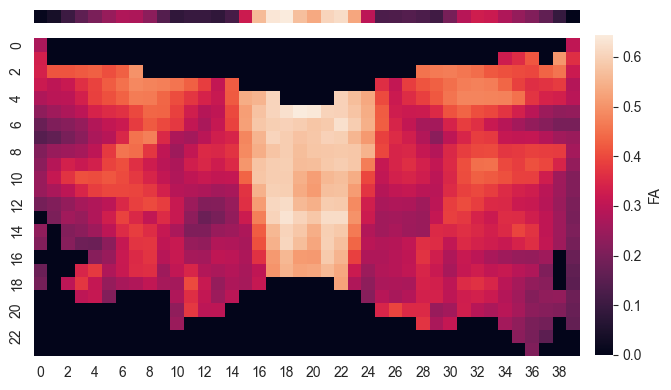

In [92]:
vmin = min(fa_profile.min(), fa_grid.min())
vmax = max(fa_profile.max(), fa_grid.max())

fig, axes = plt.subplots(
    figsize=(6, 4),
    nrows=2, ncols=1, sharex=True,
    gridspec_kw={'height_ratios': [1, fa_grid.shape[1]]}
)
cbar_ax = fig.add_axes([1.0, .1, .03, .8])

sns.heatmap(fa_profile.reshape(1, -1),
            ax=axes[0], 
            cbar=False, )
hm=sns.heatmap(fa_grid.T,
            ax=axes[1], 
            cbar=True, cbar_ax=cbar_ax,
            cbar_kws={'label': 'FA'})

plt.tight_layout()
plt.show()

<Axes: >

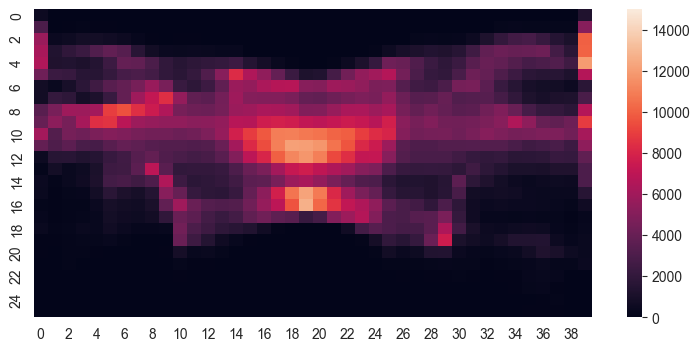

In [93]:
fig, ax = plt.subplots(figsize=(9,4))
sns.heatmap(counts.T, ax=ax, vmax=15000, cbar=True)

### Visualization segments

In [96]:
from fury import actor, window

scene = window.Scene()
scene.SetBackground(1, 1, 1)
scene.add( actor.line(
                [centroid], 
                fake_tube=True, 
                linewidth=40, 
                colors=(1, 1, 1), 
                opacity=1
            ))

# colors = alternating_colors(s_index=s_index_atlas, r_index=None, pattern=['red','black'])
colors = alternating_colors(s_index=s_index_atlas, r_index=r_index_atlas, pattern=[['red','orange'],['black','purple']])
scene.add( actor.line(
                atlas_bundle, 
                fake_tube=True, 
                linewidth=4, 
                colors=colors, 
                opacity=1
            ))

window.show(scene, size=(1200, 1200))

In [81]:
from fury import actor, window

scene = window.Scene()
scene.SetBackground(1, 1, 1)

colors = alternating_colors(s_index=s_index, r_index=r_index, valid_mask=valid_mask, pattern=[['red','orange'],['black','purple']])
# colors = make_sr_colors(s_index=s_index, r_index=None, pattern=['red','black'])
scene.add( actor.line(
                org_bundle, 
                fake_tube=True, 
                linewidth=4, 
                colors=colors, 
                opacity=1
            ))
window.show(scene, size=(1200, 1200))

### Visualize transverse vectors

In [95]:
plot_uvecs(centroid, u_vecs, 6)